<a href="https://colab.research.google.com/github/Jay-D21/Smart-Library-Chatbot/blob/main/SLCB1_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Smart Library ChatBot

A Hybrid Deep Learning Architecture for an Intelligent Library Search System With NLP

Jayesh Patil (C233)

Ritesh Pawar (C276)

Course: B.Tech (AIML) Semester V

Subjects: Deep Learning & Natural Language Processing



##Phase 1: Foundation & Data Processing


### Install necessary libraries

In [ ]:
!pip install textblob #used for tasks like spelling correction.
!pip install nltk

print("✅ Libraries installed.")

✅ Libraries installed.


### Import libraries and download NLTK data

In [ ]:
import pandas as pd
import nltk
import re  # For regular expressions (abbreviations)
import string # For punctuation
from textblob import TextBlob

# NLTK modules
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Download necessary NLTK datasets
nltk.download('punkt')      # For tokenization
nltk.download('stopwords')  # For stopword removal
nltk.download('wordnet')    # For lemmatization
nltk.download('omw-1.4')    # (Needed for WordNet)
nltk.download('punkt_tab')  # Added to fix the error

print("✅ Libraries and datasets loaded successfully.")

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


✅ Libraries and datasets loaded successfully.


[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


### Load the dataset

In [ ]:
try:
    df = pd.read_csv('master_book_dataset.csv')

    # Handle potential missing values (NaN) in text columns by replacing them with empty strings
    text_columns = ['title', 'author', 'description', 'summary', 'genre', 'keywords', 'targetAudience', 'location', 'shelf_details']
    for col in text_columns:
        if col in df.columns:
            df[col] = df[col].fillna('')

    # Display the first 5 rows and info to confirm
    print("--- DataFrame Info ---")
    print(df.info())
    print("\n--- DataFrame Head ---")
    print(df.head())

except FileNotFoundError:
    print("❌ ERROR: 'master_book_dataset.csv' not found.")
    print("Please upload the file using the 'Files' tab on the left and try again.")

--- DataFrame Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1975 entries, 0 to 1974
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   title           1975 non-null   object
 1   author          1975 non-null   object
 2   publisher       1919 non-null   object
 3   description     1975 non-null   object
 4   summary         1975 non-null   object
 5   genre           1975 non-null   object
 6   keywords        1975 non-null   object
 7   targetAudience  1975 non-null   object
 8   location        1975 non-null   object
 9   shelf_details   1975 non-null   object
dtypes: object(10)
memory usage: 154.4+ KB
None

--- DataFrame Head ---
                             title        author           publisher  \
0  HOW WILL YOU MEASURE YOUR LIFE?   CHRISTENSEN           CLAYTON M   
1               THE POWER OF HABIT        DUHIGG            CHARLES    
2            TO KILL A MOCKINGBIRD           LEE      

### Define all preprocessing functions

In [ ]:
# 1. Abbreviation Expansion
abbreviations_dict = {
    # --- CS Core (from your original list) ---
    'dsa': 'data structures and algorithms',
    'os': 'operating system',
    'dbms': 'database management system',

    # --- New CS Core ---
    'cn': 'computer networks',
    'se': 'software engineering',
    'oop': 'object-oriented programming',
    'oops': 'object-oriented programming', # common typo
    'toc': 'theory of computation',
    'algo': 'algorithms',
    'comp sci': 'computer science',
    'it': 'information technology',
    'sql': 'structured query language',
    'js': 'javascript',
    'py': 'python',

    # --- AI/ML/DL (from your original list) ---
    'dl': 'deep learning',
    'ml': 'machine learning',
    'ai': 'artificial intelligence',
    'nlp': 'natural language processing',

    # --- New AI/ML/DL ---
    'ann': 'artificial neural network',
    'cnn': 'convolutional neural network',
    'rnn': 'recurrent neural network',
    'lstm': 'long short-term memory',
    'cv': 'computer vision',
    'bi': 'business intelligence',
    'da': 'data analysis',
    'ds': 'data science',
    'genai': 'generative artificial intelligence',

    # --- General Tech & Business ---
    'iot': 'internet of things',
    'vr': 'virtual reality',
    'ar': 'augmented reality',
    'ui': 'user interface',
    'ux': 'user experience',
    'devops': 'development operations',
    'mgmt': 'management',
    'econ': 'economics',

    # --- Book Genres & Types ---
    'sci-fi': 'science fiction',
    'non-fic': 'non-fiction',
    'fic': 'fiction',
    'bio': 'biography',
    'hist': 'history',
    'psy': 'psychology',

    # --- Common Query Words ---
    'abt': 'about',
    'rec': 'recommend',
    'reco': 'recommend',
    'vs': 'versus',
    'w/': 'with',
    'w/o': 'without',
    'eg': 'for example',
    'ex': 'example',
    'info': 'information',
    'intro': 'introduction',
    'adv': 'advanced',
    'b/w': 'between'
}

# Function to replace abbreviations in the text
def expand_abbreviations(text):
    # \b stands for "word boundary" to ensure we don't replace 'ml' in 'html'
    pattern = re.compile(r'\b(' + '|'.join(re.escape(key) for key in abbreviations_dict.keys()) + r')\b', re.IGNORECASE)

    def replace_match(match):
        return abbreviations_dict[match.group(0).lower()]

    return pattern.sub(replace_match, text)

# 2. Spelling Correction
# Function to correct spelling using TextBlob
def correct_spelling(text):
    # Uses TextBlob to correct common spelling mistakes
    return str(TextBlob(text).correct())

# 3. Standard NLP Pipeline (for our LSTM model)
# Initialize NLTK tools
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))
punctuation_set = set(string.punctuation)

# Function for the standard NLP pipeline used by the LSTM model
def standard_nlp_pipeline(text):
    """
    This pipeline is for our LSTM model. It removes all "noise"
    and keeps only the root of the words (lemmas).
    """
    # 1. Tokenize the text into words
    tokens = word_tokenize(text.lower())

    # 2. Remove stop words, punctuation, and non-alphabetic tokens
    cleaned_tokens = []
    for token in tokens:
        # Check if the token is not a stop word, not punctuation, and is alphabetic
        if (token not in stop_words) and (token not in punctuation_set) and (token.isalpha()):
            # 3. Lemmatize the word (reduce to its base form)
            cleaned_tokens.append(lemmatizer.lemmatize(token))

    # Join the cleaned tokens back into a string
    return " ".join(cleaned_tokens)

# 4. Master Query Preprocessor (for our DL Search Engine)
# Function to preprocess queries for the SBERT search model
def preprocess_query_for_search(text):
    """
    This pipeline is for our SBERT search model.
    It ONLY fixes typos and acronyms. It *keeps* natural language
    (stopwords, punctuation, etc.) because SBERT is trained on it.
    """
    # 1. Expand abbreviations using the defined dictionary
    text = expand_abbreviations(text)
    # 2. Correct spelling using TextBlob
    text = correct_spelling(text)
    # Return the preprocessed text
    return text

print("✅ All processing functions are defined.")

✅ All processing functions are defined.


###Test the query preprocessing functions

In [ ]:
test_query = "sugest me sum boks on dsa" # Example query with typos and an abbreviation

# Test the function for our "smart" DL Search Engine (SBERT)
# This pipeline keeps natural language but corrects errors
search_cleaned = preprocess_query_for_search(test_query)
print(f"--- For DL Search (SBERT) ---")
print(f"Original: '{test_query}'")
print(f"Cleaned:  '{search_cleaned}'")
print("(Notice it keeps natural language, just fixes errors)")

print("\n" + "="*30 + "\n")

# Test the function for our LSTM Intent Classifier
# This pipeline removes noise like stopwords and punctuation, and lemmatizes words
lstm_cleaned = standard_nlp_pipeline(search_cleaned)
print(f"--- For DL Classifier (LSTM) ---")
print(f"Original: '{search_cleaned}'")
print(f"Cleaned:  '{lstm_cleaned}'")
print("(Notice it removes stopwords and lemmatizes)")

--- For DL Search (SBERT) ---
Original: 'sugest me sum boks on dsa'
Cleaned:  'suggest me sum books on data structures and algorithms'
(Notice it keeps natural language, just fixes errors)


--- For DL Classifier (LSTM) ---
Original: 'suggest me sum books on data structures and algorithms'
Cleaned:  'suggest sum book data structure algorithm'
(Notice it removes stopwords and lemmatizes)


### Create the "Knowledge Base" column

In [ ]:
print("Creating combined 'topic_text' column...")

# We combine all text fields to give our DL model the most context
df['topic_text'] = (df['title'] + '. ' +
                    df['description'] + ' ' +
                    df['summary'] + ' ' +
                    df['genre'] + ' ' +
                    df['keywords'] + ' ' +
                    df['targetAudience'])

print("--- Processing Complete ---")
print("Here's a sample of the new 'topic_text' column:")

# Show a sample of the data
print(df[['title', 'topic_text']].head())

Creating combined 'topic_text' column...
--- Processing Complete ---
Here's a sample of the new 'topic_text' column:
                             title  \
0  HOW WILL YOU MEASURE YOUR LIFE?   
1               THE POWER OF HABIT   
2            TO KILL A MOCKINGBIRD   
3        WHRE THE WILD COFEE GROWS   
4                       CHRONICLES   

                                          topic_text  
0  HOW WILL YOU MEASURE YOUR LIFE?. In "How Will ...  
1  THE POWER OF HABIT. Dive into the science of s...  
2  TO KILL A MOCKINGBIRD. Harper Lee's timeless c...  
3  WHRE THE WILD COFEE GROWS. Embark on a captiva...  
4   CHRONICLES. Experience the raw and poetic wor...  


##Phase 2: The Deep Learning Search Engine (Semantic Search)

### Install and import libraries for Deep Learning search

In [ ]:
!pip install -q sentence-transformers

# Import the necessary components
from sentence_transformers import SentenceTransformer, util
import torch
import numpy as np

print("✅ SentenceTransformer library installed and imported.")

✅ SentenceTransformer library installed and imported.


### Load the DL Search Model (SBERT)

In [ ]:

# Load the model. This downloads it the first time.
search_model = SentenceTransformer('all-MiniLM-L6-v2')

# Check if a GPU is available
if torch.cuda.is_available():
    search_model = search_model.to(torch.device("cuda"))
    print("✅ Model loaded successfully and moved to GPU.")
else:
    print("✅ Model loaded successfully on CPU.")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (3 outputs left out)

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

✅ Model loaded successfully and moved to GPU.


### Create Semantic Embeddings (The DL Upgrade)

In [ ]:
# 1. Get the text we want to "embed" from our DataFrame (from Phase 1)
# We use the raw 'topic_text' because SBERT understands natural language
topic_corpus = df['topic_text'].tolist()
title_corpus = df['title'].tolist()

# 2. Create 'topic_embeddings'
print(f"Embedding {len(topic_corpus)} book topics...")
# .encode() runs the text through the DL model
topic_embeddings = search_model.encode(topic_corpus, convert_to_tensor=True, show_progress_bar=True)

# 3. Create 'title_embeddings'
print(f"Embedding {len(title_corpus)} book titles...")
title_embeddings = search_model.encode(title_corpus, convert_to_tensor=True, show_progress_bar=True)

print("\n--- ✅ All Embeddings Created ---")
print(f"Topic Embeddings Shape: {topic_embeddings.shape}")
print(f"Title Embeddings Shape: {title_embeddings.shape}")

Embedding 1975 book topics...


Batches:   0%|          | 0/62 [00:00<?, ?it/s]

Embedding 1975 book titles...


Batches:   0%|          | 0/62 [00:00<?, ?it/s]


--- ✅ All Embeddings Created ---
Topic Embeddings Shape: torch.Size([1975, 384])
Title Embeddings Shape: torch.Size([1975, 384])


###Define the DL-Powered Search Function (With ALL Fields)

In [ ]:
def find_books(query, search_type='topic', top_n=3):
    """
    Finds books using our DL semantic search model.
    """

    # 1. Preprocess the query (from Phase 1)
    cleaned_query = preprocess_query_for_search(query)

    # 2. Encode the cleaned query
    query_embedding = search_model.encode(cleaned_query, convert_to_tensor=True)

    # 3. Select which embeddings to search against
    if search_type == 'topic':
        embeddings = topic_embeddings
    elif search_type == 'title':
        embeddings = title_embeddings

    # 4. Compute Cosine Similarity
    cosine_scores = util.cos_sim(query_embedding, embeddings)[0]

    # 5. Get the top_n results
    top_results = torch.topk(cosine_scores, k=top_n)

    # 6. Format and return the results
    results = []
    for score, idx in zip(top_results.values, top_results.indices):
        # Get the book details from our original DataFrame
        book_details = df.iloc[idx.item()]

        # --- THIS IS THE FIX ---
        # We now add ALL the fields our chatbot will need
        results.append({
            'title': book_details['title'],
            'author': book_details['author'],
            'summary': book_details['summary'],
            'description': book_details['description'], # <-- ADDED
            'genre': book_details['genre'],             # <-- ADDED
            'targetAudience': book_details['targetAudience'], # <-- ADDED
            'location': book_details['location'],
            'shelf_details': book_details['shelf_details'],
            'score': score.item()
        })
        # --- END OF FIX ---

    return results

print("✅ DL search function `find_books` (v2) is defined with all necessary fields.")

✅ DL search function `find_books` (v2) is defined with all necessary fields.


### Test the DL Search Function

In [ ]:
print("--- Test 1: 'Topic' Search (Broad, Semantic) ---")
# This query is conceptual. TF-IDF would fail here.
query1 = "a story about a detective solving a crime"
print(f"Query: '{query1}'")
results1 = find_books(query1, search_type='topic', top_n=3)
for res in results1:
    print(f"  - Found: {res['title']} (Score: {res['score']:.4f})")

print("\n" + "="*30 + "\n")

print("--- Test 2: 'Title' Search (Precise) ---")
# This query has an abbreviation (nlp) and a typo (lern)
query2 = "i want to lern nlp"
print(f"Query: '{query2}'")
# Our preprocessing will fix 'lern' -> 'learn' and 'nlp' -> 'natural language processing'
# Then, 'find_books' will find the most similar title.
results2 = find_books(query2, search_type='title', top_n=1)
for res in results2:
    print(f"  - Found: {res['title']} (Score: {res['score']:.4f})")
    print(f"  - Location: {res['location']}, {res['shelf_details']}")

print("\n" + "="*30 + "\n")

print("--- Test 3: 'Topic' Search with Acronym (DSA) ---")
query3 = "books on dsa"
print(f"Query: '{query3}'")
results3 = find_books(query3, search_type='topic', top_n=3)
for res in results3:
    print(f"  - Found: {res['title']} (Score: {res['score']:.4f})")

--- Test 1: 'Topic' Search (Broad, Semantic) ---
Query: 'a story about a detective solving a crime'
  - Found: DETECTIVE STORIES (Score: 0.6591)
  - Found: HERCULE PORIOT (Score: 0.5881)
  - Found: SHERLOCK HOLMES (Score: 0.5785)


--- Test 2: 'Title' Search (Precise) ---
Query: 'i want to lern nlp'
  - Found: PYTHON NATURAL LANGUAGE PROCESSING COOKBOOK (Score: 0.5727)
  - Location: REFERENCE HALL, 3/C


--- Test 3: 'Topic' Search with Acronym (DSA) ---
Query: 'books on dsa'
  - Found: DATA STRUCTURES AND ALGORITHMS (Score: 0.7317)
  - Found: DATA STRUCTURES (Score: 0.6963)
  - Found: DATA STRUCTURES AND ALGORITHMS (Score: 0.6682)


##Phase 3: The Deep Learning Classifier (The "Brain")

### Import DL Classifier & Preprocessing Libraries

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout, SpatialDropout1D
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
import numpy as np
import pickle

print(f"TensorFlow Version: {tf.__version__}")
print("✅ DL Classifier libraries imported (with EarlyStopping).")

TensorFlow Version: 2.19.0
✅ DL Classifier libraries imported (with EarlyStopping).


### Create Data with Augmentation

In [ ]:
import pandas as pd
import random

print("Generating augmented training data...")

# 1. Define our 'templates'
# These are the patterns of user queries for each intent
templates = {
    'find_location': [
        "where is {book}",
        "location of {book}",
        "find {book}",
        "can you tell me where to find {book}",
        "how do i get to {book}",
        "i need to find {book}",
        "show me the shelf for {book}",
        "what hall is {book} in?",
        "where is it?",
        "shelf number for {book} please",
        "find me {book}",
        "point me to {book}",
        "i'm looking for {book}"
    ],
    'find_topic': [
        "suggest books on {topic}",
        "recommend me a book on {topic}",
        "i want to learn about {topic}",
        "what books do you have on {topic}",
        "any good {topic} books?",
        "looking for {topic} books",
        "show me books about {topic}",
        "i need info on {topic}",
        "books abt {topic}",
        "i want to read about {topic}",
        "any books on {topic}?",
        "recommend some {topic}",
        "i need a good {topic} book"
    ],
    'get_summary': [
        "tell me about {book}",
        "what is {book} about?",
        "summary for {book}",
        "can you give me a summary of {book}",
        "describe {book}",
        "what's {book} cover?",
        "what's the plot of {book}?",
        "give me a brief of {book}",
        "can you summarize {book}?",
        "tell me more about {book}",
        "what is this book about?",
        "explain {book} to me",
        "give me the gist of {book}"
    ]
}

# 2. Define our 'fillers'
# These are example book titles and topics to insert into the templates
books = ["'how will you measure your life'", "'zero'", "'the power of habit'", "'deep learning'", "'python programming'", "'data structures'"]
topics = ["'dsa'", "'ml'", "'deep learning'", "'ai'", "'sci-fi'", "'psychology'", "'business'", "'operating system'", "'data science'",
          "'programming'", "'python'", "'cn'", "'fiction'", "'mystery'", "'nlp'", "'se'", "'iot'", "'sql'", "'econ'", "'cv'"]

# 3. Generate the data
# We loop through templates and fillers to create diverse training examples
new_data = {'query': [], 'intent': []}
for intent, tmpl_list in templates.items():
    for _ in range(150): # Create 150 examples *per intent*
        template = random.choice(tmpl_list)
        if "{book}" in template:
            query = template.format(book=random.choice(books))
        else:
            query = template.format(topic=random.choice(topics))

        new_data['query'].append(query)
        new_data['intent'].append(intent)

intent_df = pd.DataFrame(new_data)

# 4. Preprocess the *new* queries
# Apply the standard NLP pipeline for the LSTM model
intent_df['processed_query'] = intent_df['query'].apply(standard_nlp_pipeline)

print(f"✅ Created {len(intent_df)} augmented training examples.")
print("\n--- Sample of Augmented Data ---")
print(intent_df.sample(10)) # Show 10 random samples

Generating augmented training data...
✅ Created 450 augmented training examples.

--- Sample of Augmented Data ---
                                                 query         intent  \
48                    i need to find 'data structures'  find_location   
281                             any good 'econ' books?     find_topic   
145                      point me to 'data structures'  find_location   
213                               recommend some 'sql'     find_topic   
441  can you give me a summary of 'how will you mea...    get_summary   
41                                        where is it?  find_location   
56                                         find 'zero'  find_location   
340                    what's 'data structures' cover?    get_summary   
117                 what hall is 'data structures' in?  find_location   
406                           describe 'deep learning'    get_summary   

               processed_query  
48         need find structure  
281            

### Preprocess Data (Tokenize & Pad)

In [ ]:
# --- 1. Define Model Parameters ---
VOCAB_SIZE = 1000  # Max words in vocabulary. Limits the number of unique words the model considers.
EMBEDDING_DIM = 16 # Dimension of the word embedding. Each word will be represented by a vector of this size.
OOV_TOKEN = "<OOV>" # Token for "Out of Vocabulary" words. Used for words not in the top VOCAB_SIZE.

# --- 2. Encode Labels ---
labels = intent_df['intent'].values # Extract the 'intent' column as a NumPy array. This contains the text labels (e.g., 'find_location').
label_encoder = LabelEncoder() # Create an instance of the LabelEncoder. This object will learn the mapping from text labels to integers.
encoded_labels = label_encoder.fit_transform(labels) # Fit the encoder on the labels and transform them into numerical values.
num_classes = len(label_encoder.classes_) # Get the number of unique classes (intents) from the fitted encoder.

# --- 3. Tokenize Text ---
queries = intent_df['processed_query'].values # Extract the 'processed_query' column (cleaned text) as a NumPy array.
tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token=OOV_TOKEN) # Create a Tokenizer object. It will build a vocabulary of the most frequent words.
tokenizer.fit_on_texts(queries) # Builds the vocabulary based on the words in the 'queries'. Assigns a unique integer to each word.
sequences = tokenizer.texts_to_sequences(queries) # Converts the text queries into sequences of integers based on the vocabulary.

# --- 4. Pad Sequences (NEW: Auto-find MAX_SEQ_LEN) ---
# Find the length of the longest sentence
auto_max_len = max([len(x) for x in sequences])
# We'll set our MAX_SEQ_LEN to this value
MAX_SEQ_LEN = auto_max_len
print(f"Found longest sequence to be {MAX_SEQ_LEN} words. Setting as MAX_SEQ_LEN.")

padded_sequences = pad_sequences(sequences, maxlen=MAX_SEQ_LEN, padding='post', truncating='post')

# --- 5. Split Data (Train/Test) ---
X_train, X_test, y_train, y_test = train_test_split(
    padded_sequences,
    encoded_labels,
    test_size=0.2,     # 20% for testing
    random_state=42,
    stratify=encoded_labels
)

print(f"Number of classes: {num_classes}")
print(f"Shape of padded sequences (X_train): {X_train.shape}")
print(f"Shape of labels (y_train): {y_train.shape}")

Found longest sequence to be 5 words. Setting as MAX_SEQ_LEN.
Number of classes: 3
Shape of padded sequences (X_train): (360, 5)
Shape of labels (y_train): (360,)


### Define a SIMPLER, More Robust Model (Global Pooling)

In [ ]:
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.layers import GlobalAveragePooling1D


model = Sequential([
    # 1. Embedding Layer (same as before)
    Embedding(input_dim=VOCAB_SIZE,
              output_dim=EMBEDDING_DIM,
              input_length=MAX_SEQ_LEN),

    SpatialDropout1D(0.25),

    # We replace the complex LSTM with a Global Pooling layer.
    # This is MUCH better for small datasets and fights overfitting.
    GlobalAveragePooling1D(),

    # add a simple Dense layer
    Dense(24, activation='relu'),
    Dropout(0.4),

    # Output layer
    Dense(num_classes, activation='softmax')
])

# We will keep our stable optimizer
stable_optimizer = Adam(learning_rate=0.001, clipnorm=1.0) # We can try a slightly faster LR

# Compile the model
model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer=stable_optimizer,
    metrics=['accuracy']
)

model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ ?                      │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ ?                      │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

### Train the New Model

In [ ]:
print("Training the new Global Pooling model...")

# 1. Define the EarlyStopping callback
early_stopping_cb = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

# 2. Train
history = model.fit(
    X_train, y_train,
    epochs=50,
    validation_data=(X_test, y_test),
    batch_size=32,
    callbacks=[early_stopping_cb],
    verbose=2
)

print("\n✅ Model training complete.")
model.summary()

Training the new Global Pooling model...
Epoch 1/50
12/12 - 15s - 1s/step - accuracy: 0.3694 - loss: 1.0968 - val_accuracy: 0.5333 - val_loss: 1.0918
Epoch 2/50
12/12 - 0s - 28ms/step - accuracy: 0.5389 - loss: 1.0860 - val_accuracy: 0.6444 - val_loss: 1.0796
Epoch 3/50
12/12 - 0s - 32ms/step - accuracy: 0.5583 - loss: 1.0743 - val_accuracy: 0.6333 - val_loss: 1.0629
Epoch 4/50
12/12 - 0s - 23ms/step - accuracy: 0.6306 - loss: 1.0557 - val_accuracy: 0.7444 - val_loss: 1.0408
Epoch 5/50
12/12 - 0s - 17ms/step - accuracy: 0.7056 - loss: 1.0348 - val_accuracy: 0.8111 - val_loss: 1.0133
Epoch 6/50
12/12 - 0s - 25ms/step - accuracy: 0.7222 - loss: 1.0060 - val_accuracy: 0.9111 - val_loss: 0.9796
Epoch 7/50
12/12 - 0s - 15ms/step - accuracy: 0.7417 - loss: 0.9704 - val_accuracy: 0.9000 - val_loss: 0.9408
Epoch 8/50
12/12 - 0s - 18ms/step - accuracy: 0.7250 - loss: 0.9267 - val_accuracy: 0.9000 - val_loss: 0.8949
Epoch 9/50
12/12 - 0s - 14ms/step - accuracy: 0.7722 - loss: 0.8863 - val_accura

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 5, 16)          │        16,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ (None, 5, 16)          │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 16)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 24)             │           408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │            75 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 49,451 (193.17 KB)

 Trainable params: 16,483 (64.39 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 32,968 (128.79 KB)

### Visualize Training History (model.history)

Training history...


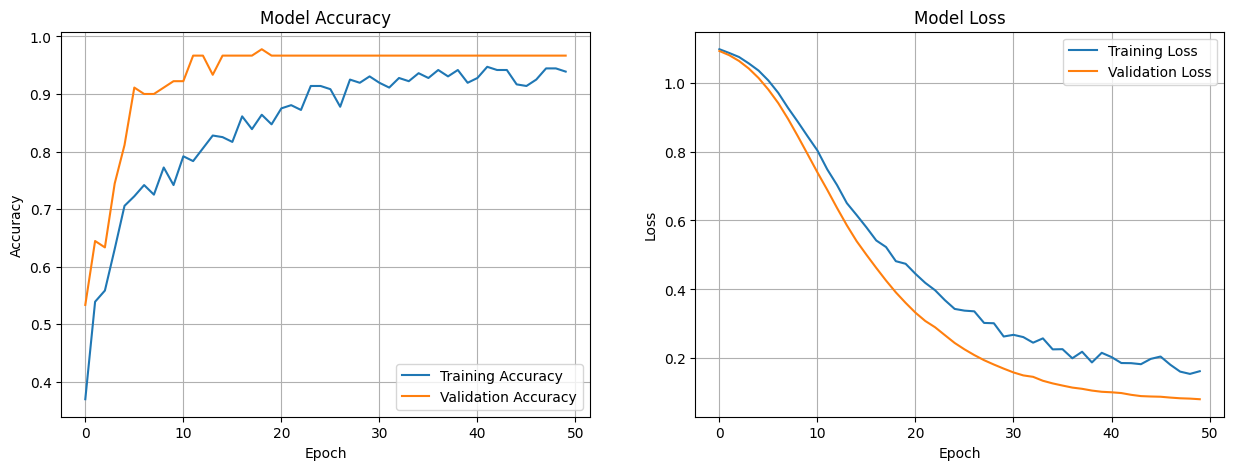

In [ ]:
print("Training history...")

# Create a figure with two subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# --- Plot 1: Model Accuracy ---
ax1.plot(history.history['accuracy'], label='Training Accuracy')
ax1.plot(history.history['val_accuracy'], label='Validation Accuracy')
ax1.set_title('Model Accuracy')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend(loc='lower right')
ax1.grid(True)

# --- Plot 2: Model Loss ---
ax2.plot(history.history['loss'], label='Training Loss')
ax2.plot(history.history['val_loss'], label='Validation Loss')
ax2.set_title('Model Loss')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend(loc='upper right')
ax2.grid(True)

# Show the plots
plt.show()

### Save the Model and Tokenizers

In [ ]:
# 1. Save the trained Keras model
model.save('intent_model.h5')

# 2. Save the Tokenizer
# Save the tokenizer object to a file using pickle
with open('tokenizer.pickle', 'wb') as handle:
    pickle.dump(tokenizer, handle, protocol=pickle.HIGHEST_PROTOCOL)

# 3. Save the Label Encoder
# Save the label_encoder object to a file using pickle
with open('label_encoder.pickle', 'wb') as handle:
    pickle.dump(label_encoder, handle, protocol=pickle.HIGHEST_PROTOCOL)

# --- THIS IS THE NEW LINE ---
# 4. Save the MAX_SEQ_LEN variable
# Save the MAX_SEQ_LEN value to a file using pickle
with open('max_seq_len.pickle', 'wb') as handle:
    pickle.dump(MAX_SEQ_LEN, handle, protocol=pickle.HIGHEST_PROTOCOL)
# --- END OF NEW LINE ---

print("✅ All Phase 3 components (model, tokenizer, encoder, max_len) saved to disk.")

✅ All Phase 3 components (model, tokenizer, encoder, max_len) saved to disk.


##Phase 4: The Generative Chatbot & Final UI

### Install Transformers and Gradio

In [ ]:
!pip install -q transformers
!pip install -q gradio

print("✅ Transformers and Gradio installed.")

✅ Transformers and Gradio installed.


### Import Generative AI and UI Libraries

In [ ]:
# Import the necessary libraries for the chatbot's generative capabilities and user interface.
from transformers import T5ForConditionalGeneration, T5Tokenizer # Libraries for the T5 text generation model.
import gradio as gr # Library for creating the web-based user interface.
import tensorflow as tf # Deep learning framework, used for loading the intent model.
import pickle # Used for loading saved Python objects (like the tokenizer and label encoder).
import numpy as np # Library for numerical operations, often used with model predictions.
from tensorflow.keras.preprocessing.sequence import pad_sequences # Needed for preparing user input for the intent model.

print("✅ All libraries for Phase 4 imported.")

✅ All libraries for Phase 4 imported.


### Load the Generative Model (T5)

In [ ]:
print("Loading generative model (t5-small)... This may take a moment.")

# Load the T5 model and its tokenizer
gen_tokenizer = T5Tokenizer.from_pretrained('t5-small') # Loads the tokenizer for the T5 model
gen_model = T5ForConditionalGeneration.from_pretrained('t5-small') # Loads the T5 model for text generation

print("✅ T5 Model loaded.")

# Define a helper function to use this model
def generate_response(prompt):
    """
    Generates a response from a prompt using the T5 model.
    """
    # 1. Tokenize the prompt
    inputs = gen_tokenizer.encode(
        prompt,
        return_tensors="pt", # Return PyTorch tensors
        max_length=512,  # Max length of the prompt
        truncation=True # Truncate if the prompt is too long
    )

    # 2. Generate the output
    outputs = gen_model.generate(
        inputs,
        max_length=150,  # Max length of the *answer*
        min_length=20,   # Min length of the *answer*
        length_penalty=2.0, # Encourage longer outputs
        num_beams=4, # Use beam search for better results
        early_stopping=True # Stop when enough beams are finished
    )

    # 3. Decode and return the text
    response = gen_tokenizer.decode(outputs[0], skip_special_tokens=True) # Decode the generated tokens back to text
    return response

print("✅ `generate_response` function defined.")

Loading generative model (t5-small)... This may take a moment.


tokenizer_config.json:   0%|          | 0.00/2.32k [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.39M [00:00<?, ?B/s]

You are using the default legacy behaviour of the <class 'transformers.models.t5.tokenization_t5.T5Tokenizer'>. This is expected, and simply means that the `legacy` (previous) behavior will be used so nothing changes for you. If you want to use the new behaviour, set `legacy=False`. This should only be set if you understand what it means, and thoroughly read the reason why this was added as explained in https://github.com/huggingface/transformers/pull/24565


config.json:   0%|          | 0.00/1.21k [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/242M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

✅ T5 Model loaded.
✅ `generate_response` function defined.


### Load Saved Intent Model and Preprocessors

In [ ]:
print("Loading saved components from Phase 3...")

# 1. Load the trained Keras model
intent_model = tf.keras.models.load_model('intent_model.h5')

# 2. Load the Tokenizer
with open('tokenizer.pickle', 'rb') as handle:
    tokenizer = pickle.load(handle)

# 3. Load the Label Encoder
with open('label_encoder.pickle', 'rb') as handle:
    label_encoder = pickle.load(handle)

# --- THIS IS THE NEW, FIXED SECTION ---
# 4. Load the MAX_SEQ_LEN
with open('max_seq_len.pickle', 'rb') as handle:
    MAX_SEQ_LEN = pickle.load(handle)
# --- END OF FIXED SECTION ---

print(f"✅ Intent model, tokenizer, and label encoder loaded.")
print(f"✅ MAX_SEQ_LEN successfully loaded as: {MAX_SEQ_LEN}")

Loading saved components from Phase 3...


✅ Intent model, tokenizer, and label encoder loaded.
✅ MAX_SEQ_LEN successfully loaded as: 5


### Define the Main Chatbot Logic

In [ ]:
print("Defining main chatbot logic ...")

# --- 1. T5 Helper Function ---

def generate_response(prompt):
    """
    Generates a response from a prompt using the T5 model.
    """
    inputs = gen_tokenizer.encode(
        prompt,
        return_tensors="pt", # Return PyTorch tensors
        max_length=512,  # Max length of the prompt
        truncation=True # Truncate if the prompt is too long
    )
    outputs = gen_model.generate(
        inputs,
        max_length=200, # Max length of the answer
        min_length=30, # Min length of the answer
        length_penalty=2.0, # Encourage longer outputs
        num_beams=4, # Use beam search for better results
        early_stopping=True # Stop when enough beams are finished
    )
    response = gen_tokenizer.decode(outputs[0], skip_special_tokens=True) # Decode the generated tokens back to text
    return response

# --- 2. The "Master" Chatbot Logic ---
# This function will be passed to Gradio's "State"
def chatbot_logic(message, history, memory_state):
    """
    This is the main function that powers the chatbot.
    It runs the full NLP/DL pipeline on a user's message.
    """

    intent = ""
    query_book = None

    # --- 3. Robust Memory Check ---
    # Check if the user is referring to a previously recommended book by number (e.g., '1', '2', '3')
    msg_clean = message.strip().lower()

    if memory_state and msg_clean in ['1', '2', '3']:
        try:
            book_index = int(msg_clean) - 1
            if 0 <= book_index < len(memory_state):
                query_book = memory_state[book_index]
                intent = "get_summary" # If a number is provided, the intent is to get the summary of that book
                print(f"DEBUG: Memory Hit (Numeric): User selected book {msg_clean}.")
        except:
            pass # Ignore if conversion fails

    # If the intent wasn't determined by a number, check if the query matches a previously recommended book title
    if not intent and memory_state:
        query = preprocess_query_for_search(message)
        best_match_book = find_books(query, search_type='title', top_n=1)[0]

        for recommended_book in memory_state:
            if best_match_book['title'] == recommended_book['title']:
                query_book = best_match_book
                intent = "get_summary" # If the query matches a recommended title, the intent is to get the summary
                print(f"DEBUG: Memory Hit (Title): User query matched '{query_book['title']}'.")
                break # Found a match, no need to check further

    # --- 4. PREDICT INTENT (If not handled by memory) ---
    if not intent:
        print("DEBUG: No memory hit. Clearing recommendations and classifying intent.")
        memory_state = [] # Clear memory if the user's query is not related to previous recommendations

        # Preprocess the query using the standard NLP pipeline for the intent model
        cleaned_lstm_query = standard_nlp_pipeline(message)
        # Convert the cleaned query into a sequence of integers using the trained tokenizer
        seq = tokenizer.texts_to_sequences([cleaned_lstm_query])
        # Pad the sequence to the maximum length expected by the model
        pad = pad_sequences(seq, maxlen=MAX_SEQ_LEN, padding='post')

        # Predict the intent using the loaded intent model
        pred = intent_model.predict(pad)

        # --- THIS IS THE FIX ---
        # It should be np.argmax, not np_argmax
        # Get the index of the highest probability and convert it back to the original intent label
        intent = label_encoder.inverse_transform([np.argmax(pred)])[0]
        # --- END OF FIX ---

    print(f"DEBUG: User Query: '{message}' -> Final Intent: '{intent}'")

    # --- 5. FACT-FINDING & RESPONSE GENERATION ---
    try:
        if intent == 'find_location':
            # If the book wasn't found in memory, search for it based on the query
            if not query_book:
                query = preprocess_query_for_search(message)
                query_book = find_books(query, search_type='title', top_n=1)[0]

            # Get the location and shelf details of the book
            location = query_book['location']
            shelf = query_book['shelf_details']

            # Construct the response text based on whether shelf details are available
            if shelf:
                response_text = f"Ah, '{query_book['title']}' by {query_book['author']}! You can find that one **in the {location}, on shelf {shelf}**."
            else:
                response_text = f"Ah, '{query_book['title']}' by {query_book['author']}! You can find that one **in the {location}**."

            return response_text, memory_state # Return the response and the current memory state

        elif intent == 'find_topic':
            # Preprocess the query for topic search
            query = preprocess_query_for_search(message)
            # Find the top 3 books related to the topic using the DL search function
            books = find_books(query, search_type='topic', top_n=3)

            # Store the recommended books in memory for future reference
            memory_state = books

            # Format the list of recommended books for the response
            book_list_str = ""
            for i, b in enumerate(books):
                shelf_info = f", on shelf {b['shelf_details']}" if b['shelf_details'] else ""
                book_list_str += f"\n{i+1}. '{b['title']}' by {b['author']} (Location: **{b['location']}{shelf_info}**)"

            # Construct the response text
            response_text = (f"I found a few great books on that topic for you:"
                             f"{book_list_str}"
                             f"\n\nYou can ask me for details on '1', '2', '3', or by asking about the title!")

            return response_text, memory_state # Return the response and the updated memory state

        elif intent == 'get_summary':
            # If the book wasn't found in memory, search for it based on the query
            if not query_book:
                query = preprocess_query_for_search(message)
                query_book = find_books(query, search_type='title', top_n=1)[0]

            # Prepare the context for the generative model using book details
            context = (
                f"Title: {query_book['title']}\n"
                f"Summary: {query_book['summary']}\n"
                f"Description: {query_book['description']}\n"
                f"Audience: {query_book['targetAudience']}"
            )

            # Craft a prompt for the generative model to extract summary and audience information
            prompt = (
                f"Context: {context}\n\n"
                f"Based *only* on the context provided, answer the following questions.\n"
                f"Question 1: What does this book tell us about?\n"
                f"Question 2: Who is this book preferred by?\n"
                f"Answer 1:\n"
                f"Answer 2:"
            )

            # Get the answer from the generative model
            generative_answer = generate_response(prompt)

            # Attempt to parse the answers from the generative model's output
            try:
                split_point = generative_answer.lower().index("answer 2:")
                answer_1 = generative_answer[len("Answer 1:"):split_point].strip()
                answer_2 = generative_answer[split_point + len("Answer 2:"):].strip()
                if not answer_1: answer_1 = query_book['summary'] # Fallback if Answer 1 is empty
                if not answer_2: answer_2 = query_book['targetAudience'] # Fallback if Answer 2 is empty
            except Exception as e:
                print(f"Error parsing T5 output: {e}. Using fallback.")
                answer_1 = query_book['summary'] # Fallback to original summary
                answer_2 = query_book['targetAudience'] # Fallback to original target audience

            # Get location and shelf details for the response
            location = query_book['location']
            shelf = query_book['shelf_details']
            if shelf:
                location_string = f"You can find this book **in the {location}, on shelf {shelf}**."
            else:
                location_string = f"You can find this book **in the {location}**."

            # Construct the final response text
            response_text = (
                f"Of course! Here are the details for **{query_book['title']}** ({query_book['genre']}):"
                f"\n\n**What it's about:** {answer_1}"
                f"\n\n**Who it's for:** {answer_2}"
                f"\n\n{location_string}"
            )

            return response_text, memory_state # Return the response and the current memory state

    except Exception as e:
        print(f"Error during processing: {e}")
        memory_state = [] # Clear memory in case of an error
        return "I'm sorry, I had a little trouble finding that in our records. Could you try rephrasing your request?", memory_state # Return an error message

print("✅ Main `chatbot_logic` (v8.1) function defined with typo fix and comments.")

Defining main chatbot logic ...
✅ Main `chatbot_logic` (v8.1) function defined with typo fix and comments.


### A Better, Modern UI (Fixed Example Input Order)

In [ ]:
print("Launching the Digital Librarian UI (v9.1)...")

# 1. Define the UI Components with a new layout
with gr.Blocks(theme=gr.themes.Soft()) as iface: # Use a clean, modern theme

    gr.Markdown("<h1 style='text-align: center; margin-bottom: 20px;'>📚 Digital Librarian (NLP + DL Project)</h1>")

    # This is our main layout: a sidebar (scale=1) and a main chat (scale=4)
    with gr.Row(equal_height=True):

        # --- Sidebar (Column 1) ---
        with gr.Column(scale=1, min_width=300):
            gr.Markdown("## About This Bot")
            gr.Markdown(
                """
                Welcome! I'm a smart librarian built with a full Deep Learning pipeline.

                - **DL Search (Phase 2):** I use an SBERT model to understand the *meaning* of your topic searches.
                - **DL Classifier (Phase 3):** I use a custom-built model to understand your *intent*.
                - **DL Generation (Phase 4):** I use a T5 model to give you these human-like, context-aware answers.
                """
            )

            gr.Markdown("--- \n ## Try These Examples:")

            # --- Main Chat (Column 2) ---
            with gr.Column(scale=4):

                # This component will store our memory (the list of books)
                # It is invisible to the user.
                memory_state = gr.State([])

                # The chatbot window
                chatbot = gr.Chatbot(
                    height=600,
                    # Add avatars for a "pro" look
                    avatar_images=('https://i.imgur.com/LhMhK5a.png', 'https://i.imgur.com/8l6b2Ok.png'),
                    bubble_full_width=False,
                    label="Chat Window"
                )

                # The input area - DEFINE msg HERE FIRST
                with gr.Row():
                    msg = gr.Textbox(
                        show_label=False,
                        placeholder="Type your question here and press Enter...",
                        scale=5,
                        container=False # Makes it look cleaner
                    )
                    submit_btn = gr.Button("Send", scale=1, variant="primary") # 'primary' makes it blue

                # The clear button for the main chat
                clear_btn = gr.ClearButton([msg, chatbot, memory_state], value="Clear Chat")

            # NOW define Examples after msg is defined
            gr.Examples(
                examples=[
                    "suggest some books on dsa",
                    "where is 'zero'",
                    "tell me about 'the power of habit'",
                    "i want to lern abt ml",
                    "books on money"
                ],
                fn=lambda x, y, z: (x, y, z), # This is a dummy function, examples will just fill the textbox
                inputs=[msg], # Pass msg as a list
                label="Click an example to try it"
            )


    # --- 2. Define the UI Logic ---

    # This function is what runs when you press Enter or click "Send"
    # It's the "bridge" to our main chatbot_logic from Cell 23
    def respond(message, chat_history, memory):
        # Call our master function from Cell 23 (v8.1)
        # It returns TWO things: the text answer, and the updated memory
        bot_message, new_memory = chatbot_logic(message, chat_history, memory)

        # Update the chat history
        chat_history.append((message, bot_message))

        # Return all the updated components
        return "", chat_history, new_memory

    # This function is used by the Examples to fill the textbox
    def example_click(example_text):
        return example_text, [], [] # Clears chat and memory when an example is clicked

    # --- 3. Connect the Components ---

    # When the user submits a message (presses Enter in the textbox)
    msg.submit(respond, [msg, chatbot, memory_state], [msg, chatbot, memory_state])

    # When the user clicks the "Send" button
    submit_btn.click(respond, [msg, chatbot, memory_state], [msg, chatbot, memory_state])

    # Connect the example buttons to the respond function
    # We need to find the gr.Examples component to hook it up
    # Note: Gradio's 'gr.Examples' doesn't directly support this.
    # The dummy function in gr.Examples will just fill the textbox.

# --- 4. Launch the App ---
iface.launch(debug=True)

Launching the Digital Librarian UI (v9.1)...


/tmp/ipython-input-2281960281.py:34: UserWarning: You have not specified a value for the `type` parameter. Defaulting to the 'tuples' format for chatbot messages, but this is deprecated and will be removed in a future version of Gradio. Please set type='messages' instead, which uses openai-style dictionaries with 'role' and 'content' keys.
  chatbot = gr.Chatbot(
/tmp/ipython-input-2281960281.py:34: DeprecationWarning: The 'bubble_full_width' parameter is deprecated and will be removed in a future version. This parameter no longer has any effect.
  chatbot = gr.Chatbot(


It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://d06c01c3aad9597bc4.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


DEBUG: No memory hit. Clearing recommendations and classifying intent.
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 283ms/step
DEBUG: User Query: 'suggest some books on dsa' -> Final Intent: 'find_topic'
DEBUG: Memory Hit (Numeric): User selected book 2.
DEBUG: User Query: '2' -> Final Intent: 'get_summary'
Error parsing T5 output: substring not found. Using fallback.
